In [2]:
import sys
sys.path.append("../acoustooptic_lab")
from analysis import System as syst
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import periodogram, welch
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

In [3]:
voltages = [1.5, 2, 3, 4, 5, 6, 7, 8, 9, 10]
mask_size = ["no", "0.6mm", "0.8mm", "0.94mm"]
bundl = syst("laser", [f"../data/20260821/20mW_{mask_size[i]}Mask_{voltages[j]}V/iter_0.tdms" for i in range(len(mask_size)) for j in range(len(voltages))], channel = "X", set_data = True)
noise = syst("noise", [f"../data/20260821/20mW_{mask_size[i]}Mask_noise/iter_0.tdms" for i in range(len(mask_size))], channel = "X", set_data = True)

17.56673095263547
8.339634823161026
10.593070474571416
15.285568175058712


(1e-16, 1e-08)

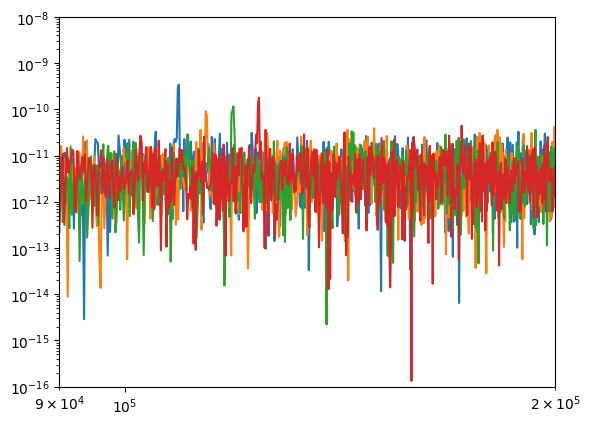

In [19]:
f, p = periodogram(bundl.get_data()[9].collection[0].x, bundl.get_data()[0].r)
plt.loglog(f, p)
sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
f, p = periodogram(noise.get_data()[0].collection[0].x, noise.get_data()[0].r)
noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
print(20 * np.log10(sig / noi))

f, p = periodogram(bundl.get_data()[19].collection[0].x, bundl.get_data()[0].r)
plt.loglog(f + 5e3, p)
sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
f, p = periodogram(noise.get_data()[0].collection[0].x, noise.get_data()[0].r)
noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
print(20 * np.log10(sig / noi))

f, p = periodogram(bundl.get_data()[29].collection[0].x, bundl.get_data()[0].r)
plt.loglog(f + 10e3, p)
sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
f, p = periodogram(noise.get_data()[0].collection[0].x, noise.get_data()[0].r)
noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
print(20 * np.log10(sig / noi))

f, p = periodogram(bundl.get_data()[39].collection[0].x, bundl.get_data()[0].r)
plt.loglog(f + 15e3, p)
sig = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
f, p = periodogram(noise.get_data()[3].collection[0].x, noise.get_data()[0].r)
noi = sum(p[find_idx(f, find_nearest(f, 108e3)):find_idx(f, find_nearest(f, 110e3))])
print(20 * np.log10(sig / noi))

plt.xlim(9e4, 2e5)
plt.ylim(1e-16, 1e-8)

In [11]:
print(bundl.get_df()[9])
print(bundl.get_df()[19])
print(bundl.get_df()[29])
print(bundl.get_df()[39])
print(noise.get_df())

../data/20260821/20mW_noMask_10V/iter_0.tdms
../data/20260821/20mW_0.6mmMask_10V/iter_0.tdms
../data/20260821/20mW_0.8mmMask_10V/iter_0.tdms
../data/20260821/20mW_0.94mmMask_10V/iter_0.tdms
['../data/20260821/20mW_noMask_noise/iter_0.tdms'
 '../data/20260821/20mW_0.6mmMask_noise/iter_0.tdms'
 '../data/20260821/20mW_0.8mmMask_noise/iter_0.tdms'
 '../data/20260821/20mW_0.94mmMask_noise/iter_0.tdms']
